# Part 3 — Communities, Robustness, and Directed Networks

This notebook connects centrality to three applied questions:

1. Which communities does the Karate Club network contain, and how do they compare with its historical split?
2. Does removing structurally important members fragment the network faster than random removal?
3. How do centrality interpretations change once ties become directed?

**Dataset:** Zachary's Karate Club (34 members). The `club` node attribute records the observed faction after the split.

In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

# Locate the repository so output paths work from the root or notebooks/.
PROJECT_ROOT = next(
    candidate for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (candidate / 'src').is_dir()
)
SEED = 42
OUTPUT_DIR = PROJECT_ROOT / 'results'
FIGURE_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

G = nx.karate_club_graph()
pos = nx.spring_layout(G, seed=SEED)
print(f'Nodes: {G.number_of_nodes()} | Edges: {G.number_of_edges()}')

Nodes: 34 | Edges: 78


## 1. Community detection and the observed split

Greedy modularity maximisation groups nodes when there are more within-group edges than a random graph with the same degree pattern would suggest. These algorithmic groups need not exactly reproduce the two factions observed by Zachary: communities describe link structure, whereas the historical outcome also depended on social conflict.

In [2]:
communities = list(nx.community.greedy_modularity_communities(G))
community_map = {node: i for i, group in enumerate(communities) for node in group}
modularity = nx.community.modularity(G, communities)

observed = nx.get_node_attributes(G, 'club')
comparison = pd.DataFrame({
    'node': sorted(G.nodes()),
    'detected_community': [community_map[n] for n in sorted(G.nodes())],
    'observed_faction': [observed[n] for n in sorted(G.nodes())],
})
contingency = pd.crosstab(comparison['detected_community'], comparison['observed_faction'])
purity = contingency.max(axis=1).sum() / len(comparison)

print(f'Detected communities: {len(communities)}')
print(f'Modularity: {modularity:.3f}')
print(f'Community-to-history purity: {purity:.1%}')
display(contingency)
comparison.to_csv(TABLE_DIR / 'community_history_comparison.csv', index=False)

Detected communities: 3
Modularity: 0.411
Community-to-history purity: 94.1%


observed_faction,Mr. Hi,Officer
detected_community,,
0,1,16
1,8,1
2,8,0


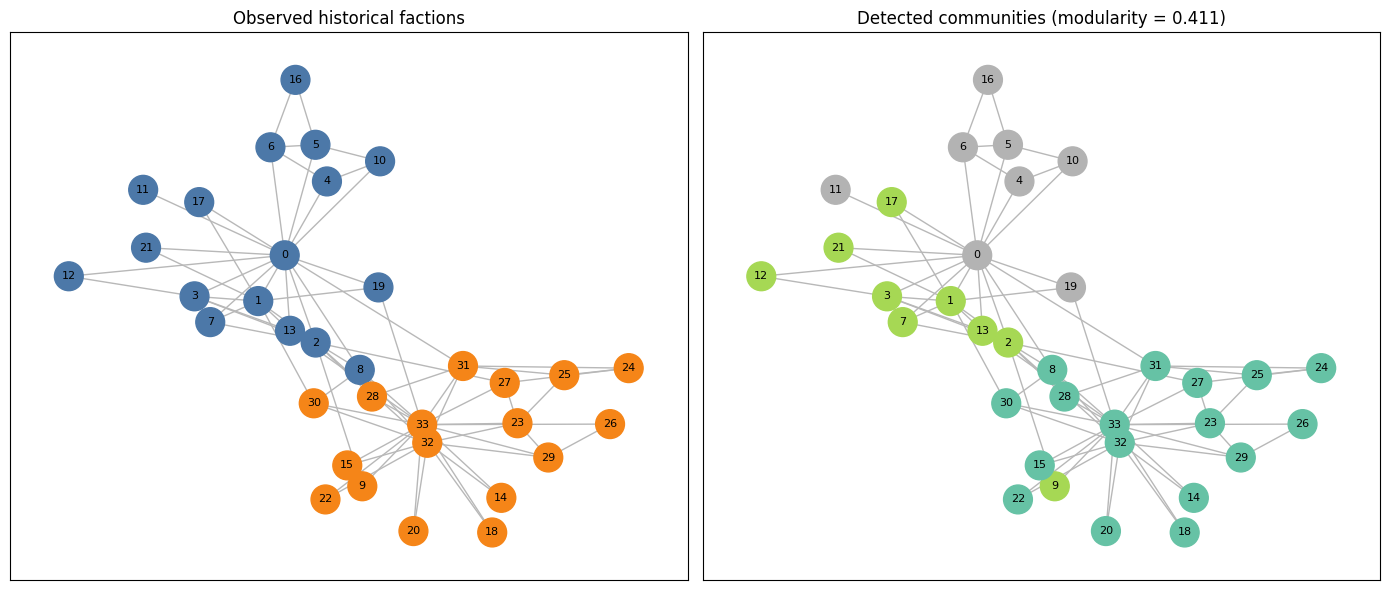

In [3]:
faction_colours = {'Mr. Hi': '#4C78A8', 'Officer': '#F58518'}
community_colours = plt.cm.Set2(np.linspace(0, 1, len(communities)))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
nx.draw_networkx(G, pos=pos, ax=axes[0], with_labels=True, node_size=430,
                 node_color=[faction_colours[observed[n]] for n in G], edge_color='#B8B8B8',
                 font_size=8)
axes[0].set_title('Observed historical factions')
nx.draw_networkx(G, pos=pos, ax=axes[1], with_labels=True, node_size=430,
                 node_color=[community_colours[community_map[n]] for n in G], edge_color='#B8B8B8',
                 font_size=8)
axes[1].set_title(f'Detected communities (modularity = {modularity:.3f})')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'community_vs_history.png', dpi=200, bbox_inches='tight')
plt.show()

### Interpretation

Use the table and diagram together. A high purity score means each detected community largely belongs to one observed faction. It does **not** mean the algorithm predicted the split perfectly: it may divide a faction into tighter subgroups, which is often meaningful social structure rather than an error.

## 2. Robustness experiment

We remove nodes sequentially and measure the fraction of original members remaining in the **largest connected component** (LCC). We compare targeted removal ordered by degree and betweenness centrality with a 100-run random baseline. If a targeted curve falls faster, that node-ranking strategy identifies members important for connectivity.

In [4]:
def lcc_fraction_after_removals(graph, removal_order):
    """Return LCC size / original node count after every removal."""
    working_graph = graph.copy()
    fractions = [1.0]
    for node in removal_order:
        working_graph.remove_node(node)
        lcc_size = max((len(c) for c in nx.connected_components(working_graph)), default=0)
        fractions.append(lcc_size / graph.number_of_nodes())
    return fractions

degree_order = [n for n, _ in sorted(G.degree(), key=lambda item: item[1], reverse=True)]
betweenness = nx.betweenness_centrality(G)
betweenness_order = sorted(betweenness, key=betweenness.get, reverse=True)

degree_curve = np.array(lcc_fraction_after_removals(G, degree_order))
betweenness_curve = np.array(lcc_fraction_after_removals(G, betweenness_order))
random_curves = []
for trial in range(100):
    order = list(G.nodes())
    random.Random(SEED + trial).shuffle(order)
    random_curves.append(lcc_fraction_after_removals(G, order))
random_curves = np.array(random_curves)
random_mean, random_std = random_curves.mean(axis=0), random_curves.std(axis=0)

robustness = pd.DataFrame({
    'nodes_removed': range(G.number_of_nodes() + 1),
    'degree_targeted_lcc_fraction': degree_curve,
    'betweenness_targeted_lcc_fraction': betweenness_curve,
    'random_mean_lcc_fraction': random_mean,
    'random_std_lcc_fraction': random_std,
})
robustness.to_csv(TABLE_DIR / 'robustness_experiment.csv', index=False)
robustness.head()

,nodes_removed,degree_targeted_lcc_fraction,betweenness_targeted_lcc_fraction,random_mean_lcc_fraction,random_std_lcc_fraction
0,0,1.000000,1.000000,1.000000,0.000000
1,1,0.970588,0.794118,0.967059,0.024706
2,2,0.764706,0.764706,0.936176,0.028532
3,3,0.588235,0.588235,0.896471,0.048947
4,4,0.294118,0.294118,0.865882,0.048919


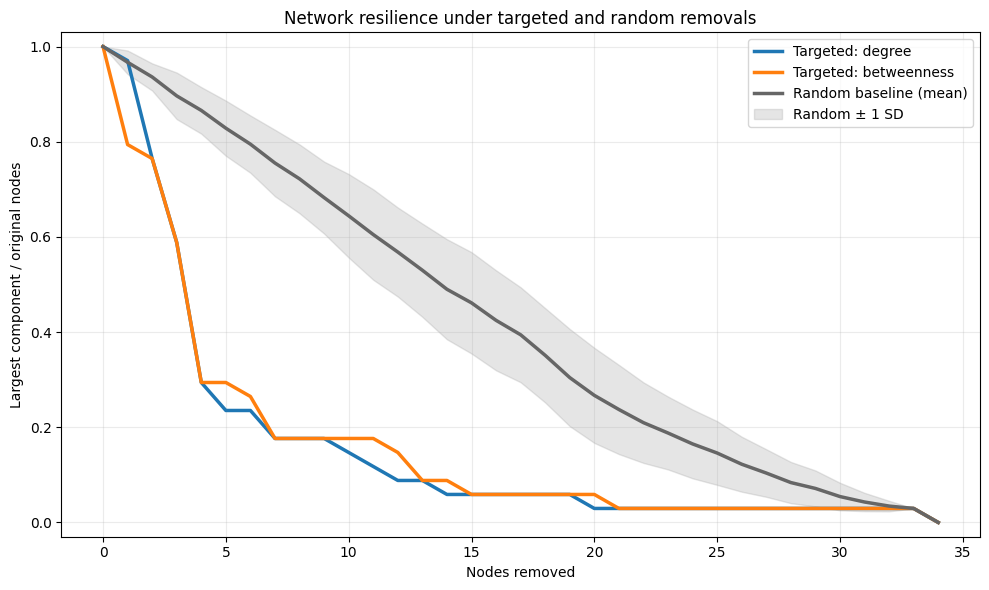

      degree: LCC first falls below 50% after 4 removals
 betweenness: LCC first falls below 50% after 4 removals
 random mean: LCC first falls below 50% after 14 removals


In [5]:
x = robustness['nodes_removed']
plt.figure(figsize=(10, 6))
plt.plot(x, degree_curve, lw=2.5, label='Targeted: degree')
plt.plot(x, betweenness_curve, lw=2.5, label='Targeted: betweenness')
plt.plot(x, random_mean, lw=2.5, label='Random baseline (mean)', color='#666666')
plt.fill_between(x, random_mean - random_std, random_mean + random_std, color='#999999', alpha=0.25, label='Random ± 1 SD')
plt.xlabel('Nodes removed')
plt.ylabel('Largest component / original nodes')
plt.title('Network resilience under targeted and random removals')
plt.ylim(-0.03, 1.03)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'robustness_targeted_vs_random.png', dpi=200, bbox_inches='tight')
plt.show()

for method, curve in [('degree', degree_curve), ('betweenness', betweenness_curve), ('random mean', random_mean)]:
    first_below_half = int(np.argmax(curve < 0.5))
    print(f'{method:>12}: LCC first falls below 50% after {first_below_half} removals')

## 3. Directed-network extension

Karate Club is undirected, so all ties are reciprocal. Social-media relationships such as following, retweeting, and replying are often directed. In the illustrative follower graph below, an arrow `A → B` means that A follows B. Therefore, high **in-degree** indicates attention received, high **out-degree** indicates following activity, and PageRank values attention from already important accounts more strongly.

,account,in_degree,out_degree,pagerank
Chitra,Chitra,7,0,0.415100
Bharat,Bharat,2,1,0.127634
Esha,Esha,2,1,0.116281
Gita,Gita,1,2,0.089568
Dev,Dev,0,2,0.062854
Asha,Asha,0,2,0.062854
Farah,Farah,0,2,0.062854
Hari,Hari,0,2,0.062854


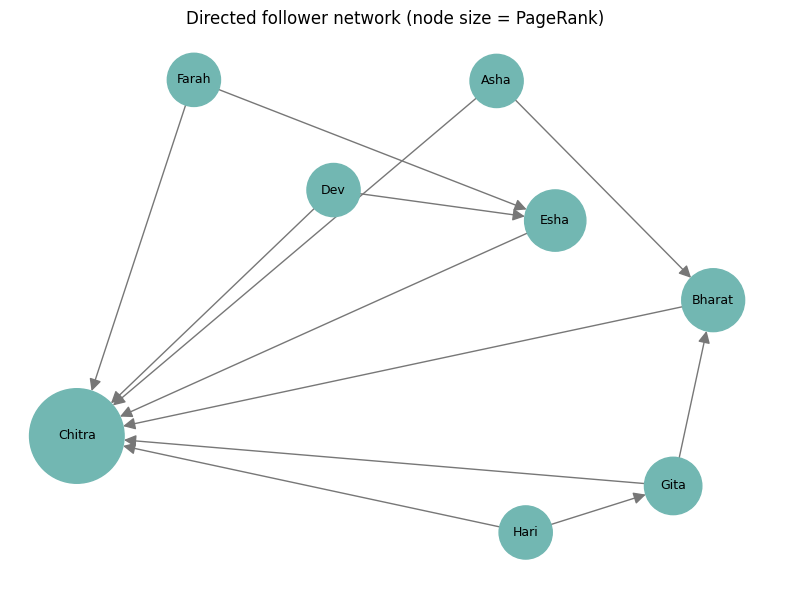

In [6]:
D = nx.DiGraph()
D.add_edges_from([
    ('Asha', 'Bharat'), ('Asha', 'Chitra'), ('Bharat', 'Chitra'),
    ('Dev', 'Chitra'), ('Dev', 'Esha'), ('Esha', 'Chitra'),
    ('Farah', 'Chitra'), ('Farah', 'Esha'), ('Gita', 'Chitra'),
    ('Gita', 'Bharat'), ('Hari', 'Chitra'), ('Hari', 'Gita'),
])

directed_scores = pd.DataFrame({
    'account': list(D.nodes()),
    'in_degree': [D.in_degree(n) for n in D],
    'out_degree': [D.out_degree(n) for n in D],
    'pagerank': pd.Series(nx.pagerank(D, alpha=0.85)),
}).sort_values('pagerank', ascending=False)
display(directed_scores)
directed_scores.to_csv(TABLE_DIR / 'directed_network_scores.csv', index=False)

directed_pos = nx.spring_layout(D, seed=SEED)
sizes = [900 + 9000 * nx.pagerank(D, alpha=0.85)[n] for n in D]
plt.figure(figsize=(8, 6))
nx.draw_networkx(D, pos=directed_pos, node_size=sizes, node_color='#72B7B2',
                 edge_color='#777777', arrows=True, arrowsize=18, font_size=9)
plt.title('Directed follower network (node size = PageRank)')
plt.axis('off')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'directed_network_pagerank.png', dpi=200, bbox_inches='tight')
plt.show()

## Conclusions

- Community detection exposes subgroups in the social structure and can be compared, rather than assumed identical, to the observed faction labels.
- Targeted removal tests a practical meaning of centrality: nodes ranked highly by degree or betweenness can be disproportionately important to network connectivity.
- The random baseline is essential: a falling LCC alone is expected whenever any nodes are removed.
- In directed graphs, receiving ties, sending ties, and receiving prestige from important accounts are distinct behaviours.

**Limitations:** Karate Club is small and undirected. Future work could repeat this pipeline on a larger interaction network, use time-resolved edges, and combine structural roles with post text, sentiment, or topics.